<a href="https://colab.research.google.com/github/sharmi510/Data-Mining/blob/main/KNN_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Lab 3's Session for CMP7206 Data Mining

# Sharmila Sankar

# Classification and its metrics



# Learning Outcomes

* Review Python concepts

* Working on EDA

* Implementing KNN classifer with two cyber security datasets

* Understand the classifications metrics


## Python Review

Python Conditions and If statements
Python supports the usual logical conditions from mathematics:

* Equals: a == b
* Not Equals: a != b
* Less than: a < b
* Less than or equal to: a <= b
* Greater than: a > b
* Greater than or equal to: a >= b

These conditions can be used in several ways, most commonly in "if statements" and loops

Ecxercise1

Use different value for `a` and `b` and use some of logical conditions from mathematics above.

In [2]:
# Add your code for Ecercise1 here

a = 10
b = 5

print(a == b)  # Equals
print(a != b)  # Not equals
print(a < b)   # Less than
print(a <= b)  # Less than or equal to
print(a > b)   # Greater than
print(a >= b)  # Greater than or equal to


False
True
False
False
True
True


***Review array concept***

* What is an Array?

* An array is a special variable, which can hold more than one value at a time.

* If you have a list of items (a list of car names, for example), storing the cars in single variables could look like this:

# You need to write this code before adding you code:
car1 = "Ford"
car2 = "Volvo"
car3 = "BMW"

However, what if you want to loop through the cars and find a specific one? And what if you had not 3 cars, but 300?

The solution is an array!

An array can hold many values under a single name, and you can access the values by referring to an index number.

In [3]:
# Create the array (list)
cars = ["Ford", "Volvo", "BMW"]

# Access element 1 and 2 in the array
print(cars[1])
print(cars[2])

# Replace element 0
cars[0] = "Toyota"
print(cars)

# Print the length of the array
print(len(cars))




Volvo
BMW
['Toyota', 'Volvo', 'BMW']
3


***Review For loop, If condition and logical mathimatical statment***

Write code using `For loop` iterating over a sequence of `list` of fruits (choose three fruits such Apple, banana and orange)

print each item of your list and break when you reach to second item which banana in this case!



In [4]:
# write your code here
fruits = ["Apple", "Banana", "Orange"]

for fruit in fruits:
    print(fruit)

    if fruit == "Banana":
        break

Apple
Banana


In this lab's session, we will work on EDA and KNN using Scikit-learn.

a step‐by‐step outline you can follow for both a Spam vs. Unspam task and an Intrusion vs. Normal task using:

1. pandas to read CSV

2. matplotlib to visualize

3. scikit-learn’s KNN to classify

In [6]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix


In [7]:
# 2. Load your CSV
# Example for spam dataset
# Example for intrusion dataset
spam_df = pd.read_csv('../Cybersecurity Intrusion Detection.csv')


In [8]:
# 3. Quick data exploration
# See first few rows
print(spam_df.head())
print(spam_df['protocol_type'].value_counts())



  session_id  network_packet_size protocol_type  login_attempts  \
0  SID_00001                  599           TCP               4   
1  SID_00002                  472           TCP               3   
2  SID_00003                  629           TCP               3   
3  SID_00004                  804           UDP               4   
4  SID_00005                  453           TCP               5   

   session_duration encryption_used  ip_reputation_score  failed_logins  \
0        492.983263             DES             0.606818              1   
1       1557.996461             DES             0.301569              0   
2         75.044262             DES             0.739164              2   
3        601.248835             DES             0.123267              0   
4        532.540888             AES             0.054874              1   

  browser_type  unusual_time_access  attack_detected  
0         Edge                    0                1  
1      Firefox                    0 

Questions to ask yourself:
1. Are there missing values?

2. Is the data balanced (similar numbers of each class)?

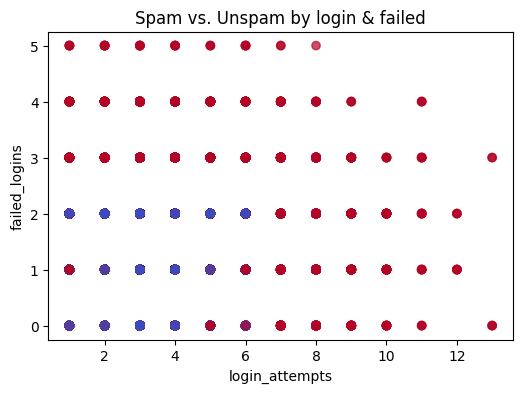

In [9]:
## Visualize with matplotlib
#Pick two numeric features (e.g. “length” vs. “num_links” in spam):

plt.figure(figsize=(6,4))
plt.scatter(spam_df['login_attempts'], spam_df['failed_logins'],
            c=spam_df['attack_detected'],
            cmap='coolwarm', alpha=0.7)
plt.xlabel('login_attempts')
plt.ylabel('failed_logins')
plt.title('Spam vs. Unspam by login & failed')
plt.show()


In [13]:
intrusion_df = pd.read_csv('../Cybersecurity Intrusion Detection.csv')

In [15]:
# Pre-process & split
# Features / labels for spam
X_spam = spam_df[['login_attempts','failed_logins']]
y_spam = spam_df['attack_detected']

# # Features / labels for intrusion
X_int = intrusion_df[['ip_reputation_score','network_packet_size']]
y_int = intrusion_df['attack_detected']

# Split (80% train / 20% test)
Xsp_train, Xsp_test, ysp_train, ysp_test = train_test_split(
    X_spam, y_spam, test_size=0.2, random_state=42)

Xint_train, Xint_test, yint_train, yint_test = train_test_split(
   X_int, y_int, test_size=0.2, random_state=42)


In [16]:
# Train a KNN classifier
# Instantiate with k=5
knn_spam = KNeighborsClassifier(n_neighbors=5)
knn_spam.fit(Xsp_train, ysp_train)

# knn_int = KNeighborsClassifier(n_neighbors=5)
# knn_int.fit(Xint_train, yint_train)


KNeighborsClassifier()

In [17]:
# Evaluate performance
# Spam
ysp_pred = knn_spam.predict(Xsp_test)
print("Spam classification report:")
print(classification_report(ysp_test, ysp_pred))
print("Confusion matrix:\n", confusion_matrix(ysp_test, ysp_pred))

# # Intrusion
# yint_pred = knn_int.predict(Xint_test)
# print("Intrusion classification report:")
# print(classification_report(yint_test, yint_pred))
# print("Confusion matrix:\n", confusion_matrix(yint_test, yint_pred))


Spam classification report:
              precision    recall  f1-score   support

           0       0.75      0.79      0.77      1042
           1       0.73      0.68      0.71       866

    accuracy                           0.74      1908
   macro avg       0.74      0.74      0.74      1908
weighted avg       0.74      0.74      0.74      1908

Confusion matrix:
 [[827 215]
 [274 592]]


***Summary***

1. Import all needed libraries

2. Load your CSV into a pandas DataFrame

3. Explore: .head(), .info(), .value_counts()

4. Visualize raw data with matplotlib scatter plots

5. Pre-process: select features & encode labels

6. Split into train/test sets

7. Train KNN (.fit)

8. Predict & evaluate with classification report & confusion matrix

9. Save the model.

10. Plot decision boundaries to see how KNN partitions feature space (optional).

# **Your Task**
1. To understand the previous steps with **Spam dataset** and do the same with the **intrusion dataset**.
2. Download the datasets from the lab folder in Week3.
3. After your implement the **EDA** and **KNN**, try to save the model (this will really help in CW1)
4. Don't forget to submit your work to Week3 submission point.

In [19]:
import pickle
model = pickle.dumps(knn_spam)